In [1]:
import sys, subprocess
def _pip(p):
    subprocess.check_call([sys.executable,"-m","pip","install","-q",*p])
try:
    import yfinance, torch, scipy, sklearn  # noqa
except Exception:
    _pip(["yfinance>=0.2.40","pandas>=2.0","numpy>=1.24","scipy>=1.10",
          "scikit-learn>=1.3","matplotlib>=3.7","torch>=2.1"])
print("environment ready")


environment ready


In [2]:
import os, math, random, time, warnings
from dataclasses import dataclass
from collections import Counter
import numpy as np, pandas as pd
import yfinance as yf
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F

warnings.filterwarnings("ignore")
pd.set_option("display.width",140); pd.set_option("display.max_columns",40)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch:", torch.__version__, "| device:", DEVICE)


torch: 2.10.0+cu128 | device: cuda


In [3]:
@dataclass
class CFG:
    start:         str   = "2010-01-01"
    end:           str   = "2025-01-01"
    horizons:      tuple = (5, 10)
    hold_days:     int   = 5
    corr_window:   int   = 60
    knn_k:         int   = 6
    hidden:        int   = 192
    n_layers:      int   = 3
    dropout:       float = 0.30
    lr:            float = 1e-3
    weight_decay:  float = 1e-4
    max_epochs:    int   = 45
    warmup_epochs: int   = 3
    swa_window:    int   = 5                  # +/- this many epochs around best val IC
    batch_dates:   int   = 32
    n_seeds:       int   = 3
    ts_norm_win:   int   = 252
    pred_smooth_days: int = 5
    wf_test_years: tuple = (2020, 2021, 2022, 2023, 2024)
    # --- v5 volatility-targeting additions ---
    vol_target_ann:   float = 0.12             # 12% annualised
    vol_lookback:     int   = 21               # days of realised vol estimator
    vol_ewm_halflife: int   = 21               # EWM half-life for vol estimator
    vol_scale_cap:    float = 3.0              # clamp daily scale in [1/cap, cap]

cfg = CFG()
print(cfg)


CFG(start='2010-01-01', end='2025-01-01', horizons=(5, 10), hold_days=5, corr_window=60, knn_k=6, hidden=192, n_layers=3, dropout=0.3, lr=0.001, weight_decay=0.0001, max_epochs=45, warmup_epochs=3, swa_window=5, batch_dates=32, n_seeds=3, ts_norm_win=252, pred_smooth_days=5, wf_test_years=(2020, 2021, 2022, 2023, 2024), vol_target_ann=0.12, vol_lookback=21, vol_ewm_halflife=21, vol_scale_cap=3.0)


In [4]:
SECTOR = {
  # Information Technology (20)
  "AAPL":"IT","MSFT":"IT","NVDA":"IT","AVGO":"IT","ORCL":"IT","CRM":"IT",
  "ADBE":"IT","CSCO":"IT","INTC":"IT","AMD":"IT","QCOM":"IT","TXN":"IT",
  "IBM":"IT","NOW":"IT","INTU":"IT","AMAT":"IT","KLAC":"IT","LRCX":"IT","MU":"IT","ACN":"IT",
  # Communication Services (7)
  "GOOGL":"COMM","META":"COMM","NFLX":"COMM","T":"COMM","VZ":"COMM","DIS":"COMM","CMCSA":"COMM",
  # Consumer Discretionary (12)
  "TSLA":"DISC","AMZN":"DISC","NKE":"DISC","SBUX":"DISC","TGT":"DISC",
  "HD":"DISC","LOW":"DISC","MCD":"DISC","BKNG":"DISC","MAR":"DISC","YUM":"DISC","EBAY":"DISC",
  # Financials (14)
  "JPM":"FIN","BAC":"FIN","WFC":"FIN","GS":"FIN","MS":"FIN","C":"FIN",
  "AXP":"FIN","BLK":"FIN","SCHW":"FIN","USB":"FIN","PNC":"FIN","COF":"FIN","SPGI":"FIN","CME":"FIN",
  # Health Care (15)
  "JNJ":"HC","PFE":"HC","MRK":"HC","ABBV":"HC","LLY":"HC","TMO":"HC",
  "UNH":"HC","CVS":"HC","BMY":"HC","AMGN":"HC","DHR":"HC","ISRG":"HC","GILD":"HC","MDT":"HC","SYK":"HC",
  # Energy (8)
  "XOM":"ENRG","CVX":"ENRG","COP":"ENRG","SLB":"ENRG","EOG":"ENRG","OXY":"ENRG","MPC":"ENRG","PSX":"ENRG",
  # Consumer Staples (10)
  "PG":"STPL","KO":"STPL","PEP":"STPL","WMT":"STPL","COST":"STPL",
  "CL":"STPL","MO":"STPL","MDLZ":"STPL","KMB":"STPL","GIS":"STPL",
  # Industrials (12)
  "BA":"IND","CAT":"IND","GE":"IND","HON":"IND","UPS":"IND","FDX":"IND",
  "LMT":"IND","RTX":"IND","DE":"IND","ETN":"IND","EMR":"IND","NOC":"IND",
  # Utilities (8)
  "NEE":"UTIL","DUK":"UTIL","SO":"UTIL","D":"UTIL","AEP":"UTIL","EXC":"UTIL","SRE":"UTIL","XEL":"UTIL",
  # Real Estate (5)
  "SPG":"RE","PSA":"RE","AMT":"RE","EQR":"RE","O":"RE",
  # Materials (7)
  "LIN":"MAT","SHW":"MAT","APD":"MAT","ECL":"MAT","FCX":"MAT","DOW":"MAT","NUE":"MAT",
}
UNIVERSE = list(SECTOR.keys())
print(f"universe = {len(UNIVERSE)}  sectors = {len(set(SECTOR.values()))}")
print("sector counts:", Counter(SECTOR.values()))


universe = 118  sectors = 11
sector counts: Counter({'IT': 20, 'HC': 15, 'FIN': 14, 'DISC': 12, 'IND': 12, 'STPL': 10, 'ENRG': 8, 'UTIL': 8, 'COMM': 7, 'MAT': 7, 'RE': 5})


In [5]:
def pull_prices(tickers, start, end):
    raw = yf.download(tickers, start=start, end=end, auto_adjust=True,
                      progress=False, group_by="ticker", threads=True)
    frames = {}
    for t in tickers:
        try: df = raw[t].copy()
        except Exception: continue
        if df.empty: continue
        df = df.rename(columns=str.lower)
        keep = [c for c in ("open","high","low","close","volume") if c in df.columns]
        df = df[keep].dropna()
        if len(df) < 252*3: continue
        frames[t] = df
    return frames

t0 = time.time()
prices = pull_prices(UNIVERSE, cfg.start, cfg.end)
print(f"downloaded {len(prices)} of {len(UNIVERSE)} names in {time.time()-t0:.1f}s")
missing = sorted(set(UNIVERSE) - set(prices))
if missing: print("missing (short history):", missing)


downloaded 118 of 118 names in 7.9s


In [6]:
def rsi(close, n=14):
    d = close.diff()
    up = d.clip(lower=0).rolling(n).mean()
    dn = (-d.clip(upper=0)).rolling(n).mean()
    rs = up / dn.replace(0, np.nan)
    return 100 - 100/(1+rs)

FEATS = [
    "ret_1d","ret_5d","ret_10d","ret_21d","ret_63d","ret_126d",
    "mom_12_1","str_1d",
    "vol_21d","vol_63d","vvol_21",
    "rsi_14","rsi_28",
    "hl_spread","oc_spread",
    "p_to_ma21","p_to_ma63","p_to_ma252",
    "vol_ratio_21","dollar_vol_z",
]

def featurize(df):
    o = pd.DataFrame(index=df.index); c = df["close"]
    o["ret_1d"]       = c.pct_change()
    o["ret_5d"]       = c.pct_change(5)
    o["ret_10d"]      = c.pct_change(10)
    o["ret_21d"]      = c.pct_change(21)
    o["ret_63d"]      = c.pct_change(63)
    o["ret_126d"]     = c.pct_change(126)
    o["mom_12_1"]     = c.pct_change(252) - c.pct_change(21)
    o["str_1d"]       = -o["ret_1d"]
    o["vol_21d"]      = o["ret_1d"].rolling(21).std()
    o["vol_63d"]      = o["ret_1d"].rolling(63).std()
    o["vvol_21"]      = o["vol_21d"].rolling(21).std()
    o["rsi_14"]       = rsi(c, 14)
    o["rsi_28"]       = rsi(c, 28)
    o["hl_spread"]    = (df["high"]-df["low"]) / c
    o["oc_spread"]    = (df["close"]-df["open"]) / df["open"]
    o["p_to_ma21"]    = c / c.rolling(21).mean()  - 1.0
    o["p_to_ma63"]    = c / c.rolling(63).mean()  - 1.0
    o["p_to_ma252"]   = c / c.rolling(252).mean() - 1.0
    o["vol_ratio_21"] = df["volume"] / df["volume"].rolling(21).mean()
    dv = (c * df["volume"]).rolling(21).mean()
    o["dollar_vol_z"] = (dv - dv.rolling(252).mean()) / dv.rolling(252).std().replace(0, np.nan)
    for h in cfg.horizons:
        o[f"fwd_ret_{h}d"] = c.pct_change(h).shift(-h)
    return o

panel = {t: featurize(df) for t, df in prices.items()}
print(f"{len(FEATS)} features built on {len(panel)} names")


20 features built on 118 names


In [7]:
def ts_normalize(df, cols, win=252):
    out = df.copy()
    for c in cols:
        r = df[c].rolling(win, min_periods=win//4)
        mu = r.mean(); sd = r.std().replace(0, np.nan)
        out[c] = ((df[c] - mu) / sd).clip(-5, 5)
    return out

panel_n = {t: ts_normalize(df, FEATS, cfg.ts_norm_win) for t, df in panel.items()}

rows = []
for t, df in panel_n.items():
    tmp = df.copy(); tmp["ticker"] = t
    rows.append(tmp.reset_index().rename(columns={"Date":"date","index":"date"}))
long = pd.concat(rows, ignore_index=True)
long["date"]   = pd.to_datetime(long["date"])
long["sector"] = long["ticker"].map(SECTOR)

needed = FEATS + [f"fwd_ret_{h}d" for h in cfg.horizons]
long = long.dropna(subset=needed).sort_values(["date","ticker"]).reset_index(drop=True)
long[FEATS] = long[FEATS].fillna(0.0)
print("long panel:", long.shape, "  dates:", long["date"].nunique(), "  avg names/day:",
      round(len(long)/long["date"].nunique(),1))


long panel: (399467, 25)   dates: 3431   avg names/day: 116.4


## Target — multi-horizon, sector-demeaned, universe-wide rank

Identical to v4. For each horizon h ∈ {5, 10}: forward-return → sector-demean per date → universe rank → centre to [-1, 1]. Final target is the mean of the two horizon ranks.


In [8]:
def cs_rank(s):
    r = s.rank(pct=True); return (r - 0.5) * 2.0

targets = []
for h in cfg.horizons:
    col = f"fwd_ret_{h}d"
    long[f"sn_{h}d"] = long.groupby(["date","sector"])[col].transform(lambda s: s - s.mean())
    long[f"y_{h}d"]  = long.groupby("date")[f"sn_{h}d"].transform(cs_rank)
    targets.append(f"y_{h}d")

long["y"] = long[targets].mean(axis=1)
print("target stats:", long["y"].describe()[["mean","std","min","max"]].round(3).to_dict())


target stats: {'mean': 0.009, 'std': 0.527, 'min': -0.983, 'max': 1.0}


## Weighted graph — sector edges ⊔ correlation kNN

Adjacency per date: sector edges at weight 1.0 ⊔ cross-sector kNN (k=6, 60d corr window) with weight = max(corr, 0). Union, symmetrise, row-normalise.


In [9]:
ret_wide = (pd.concat({t: df["close"] for t,df in prices.items()}, axis=1)
              .sort_index().pct_change()).astype("float32")
ret_wide = ret_wide.reindex(sorted(long["date"].unique()))

def build_sector_weights(tickers):
    secs = np.array([SECTOR[t] for t in tickers])
    A = (secs[:,None] == secs[None,:]).astype("float32")
    np.fill_diagonal(A, 0.0)
    return A

def build_knn_weighted(corr, k):
    C = corr.values.astype("float32").copy()
    np.fill_diagonal(C, -np.inf)
    n = C.shape[0]; k = min(k, n-1)
    idx = np.argpartition(-C, kth=k, axis=1)[:, :k]
    rows = np.repeat(np.arange(n), k)
    A = np.zeros_like(C)
    vals = C[rows, idx.ravel()]
    A[rows, idx.ravel()] = np.clip(vals, 0.0, None)
    return np.maximum(A, A.T)

def row_normalize(A, eps=1e-8):
    d = A.sum(1, keepdims=True); return A / (d + eps)

def make_snapshots(long_df, ret_wide, feats, window, k):
    snaps = {}
    for d in long_df["date"].unique():
        g = long_df[long_df["date"] == d]
        tickers = g["ticker"].tolist()
        if len(tickers) < 20: continue
        past = ret_wide.loc[:d, tickers].iloc[-(window+1):-1]
        if past.shape[0] < window//2: continue
        corr = past.corr().fillna(0.0)
        A_sec = build_sector_weights(tickers)
        A_knn = build_knn_weighted(corr, k=k)
        A = np.maximum(A_sec, A_knn).astype("float32")
        A = row_normalize(A)
        X = g.set_index("ticker").loc[tickers, feats].values.astype("float32")
        y = g.set_index("ticker").loc[tickers, "y"].values.astype("float32")
        snaps[pd.Timestamp(d)] = (tickers, A, X, y)
    return snaps

t0 = time.time()
snaps = make_snapshots(long, ret_wide, FEATS, cfg.corr_window, cfg.knn_k)
print(f"built {len(snaps)} date-graphs in {time.time()-t0:.1f}s")


built 3401 date-graphs in 10.9s


In [10]:
class GINLayer(nn.Module):
    def __init__(self, d, dropout=0.3):
        super().__init__()
        self.eps  = nn.Parameter(torch.zeros(1))
        self.norm = nn.LayerNorm(d)
        self.mlp  = nn.Sequential(
            nn.Linear(d, d*2), nn.LayerNorm(d*2), nn.GELU(),
            nn.Dropout(dropout), nn.Linear(d*2, d))
    def forward(self, H, A):
        h = self.norm(H)
        return self.mlp((1.0 + self.eps) * h + A @ h)

class GINAlpha(nn.Module):
    def __init__(self, n_feats, hidden, n_layers, dropout):
        super().__init__()
        self.in_proj = nn.Linear(n_feats, hidden)
        self.layers  = nn.ModuleList([GINLayer(hidden, dropout) for _ in range(n_layers)])
        self.head    = nn.Sequential(
            nn.LayerNorm(hidden), nn.Linear(hidden, hidden//2),
            nn.GELU(), nn.Dropout(dropout), nn.Linear(hidden//2, 1))
    def forward(self, H, A):
        h = self.in_proj(H)
        for layer in self.layers:
            h = h + layer(h, A)
        return self.head(h).squeeze(-1)


In [11]:
def block_diag_batch(dates, snaps):
    Hs, ys, sizes = [], [], []
    for d in dates:
        _, A, X, y = snaps[d]
        Hs.append(torch.from_numpy(X)); ys.append(torch.from_numpy(y))
        sizes.append(A.shape[0])
    H = torch.cat(Hs, 0); y = torch.cat(ys, 0); N = H.shape[0]
    A_big = torch.zeros(N, N, dtype=torch.float32); c = 0
    for d, n in zip(dates, sizes):
        _, A, _, _ = snaps[d]
        A_big[c:c+n, c:c+n] = torch.from_numpy(A); c += n
    return H, A_big, y, sizes

def listwise_ic_loss(pred, tgt, sizes):
    losses, c = [], 0
    for n in sizes:
        p = pred[c:c+n]; t = tgt[c:c+n]
        p = p - p.mean(); t = t - t.mean()
        denom = (p.norm() * t.norm()).clamp_min(1e-8)
        losses.append(-(p * t).sum() / denom); c += n
    return torch.stack(losses).mean()

def warmup_cosine(epoch, warmup, total, lr_max):
    if epoch < warmup: return lr_max * (epoch+1) / max(1, warmup)
    prog = (epoch - warmup) / max(1, total - warmup)
    return 0.5 * lr_max * (1 + math.cos(math.pi * prog))


## Training


In [12]:
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

def ic_on(model, dates, snaps):
    model.eval(); preds, ys = [], []
    with torch.no_grad():
        for d in dates:
            _, A, X, y = snaps[d]
            H  = torch.from_numpy(X).to(DEVICE); Ad = torch.from_numpy(A).to(DEVICE)
            preds.append(model(H, Ad).cpu().numpy()); ys.append(y)
    p = np.concatenate(preds); y = np.concatenate(ys)
    ic, _ = spearmanr(p, y); return float(ic)

def average_states(states):
    """Uniform average of a list of state_dicts. Assumes identical keys/shapes."""
    out = {k: v.clone().float() for k, v in states[0].items()}
    for st in states[1:]:
        for k in out:
            out[k] += st[k].float()
    for k in out:
        out[k] /= len(states)
    # cast back to original dtypes
    for k, v in states[0].items():
        out[k] = out[k].to(v.dtype)
    return out

def train_one_swa_best(seed, snaps, tr_dates, vl_dates):
    """Train all epochs, record every epoch's weights + val IC, then average
    weights in a +/- cfg.swa_window window centred on the best-val-IC epoch."""
    set_seed(seed)
    model = GINAlpha(len(FEATS), cfg.hidden, cfg.n_layers, cfg.dropout).to(DEVICE)
    opt   = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)

    snapshots, val_ics = [], []
    for epoch in range(cfg.max_epochs):
        lr_now = warmup_cosine(epoch, cfg.warmup_epochs, cfg.max_epochs, cfg.lr)
        for pg in opt.param_groups: pg["lr"] = lr_now
        model.train()
        order = tr_dates[:]; random.shuffle(order)
        losses = []
        for i in range(0, len(order), cfg.batch_dates):
            chunk = order[i:i+cfg.batch_dates]
            H, A, y, sizes = block_diag_batch(chunk, snaps)
            H, A, y = H.to(DEVICE), A.to(DEVICE), y.to(DEVICE)
            loss = listwise_ic_loss(model(H, A), y, sizes)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); losses.append(loss.item())
        # record everything
        snapshots.append({k: v.detach().cpu().clone() for k, v in model.state_dict().items()})
        vic = ic_on(model, vl_dates, snaps); val_ics.append(vic)
        if epoch % 5 == 0 or epoch == cfg.max_epochs-1:
            print(f"    seed={seed} ep={epoch:02d} lr={lr_now:.1e} "
                  f"loss={np.mean(losses):+.3f} val_IC={vic:+.4f}")

    # find best-val-IC epoch and average around it
    best_ep   = int(np.argmax(val_ics))
    w         = cfg.swa_window
    lo, hi    = max(0, best_ep - w), min(len(snapshots), best_ep + w + 1)
    window    = snapshots[lo:hi]
    swa_state = average_states(window) if len(window) >= 2 else snapshots[best_ep]
    model.load_state_dict(swa_state)
    swa_val = ic_on(model, vl_dates, snaps)
    print(f"    seed={seed} best_ep={best_ep} window=[{lo},{hi}) "
          f"best_epoch_val_IC={val_ics[best_ep]:+.4f}  SWA_window_val_IC={swa_val:+.4f}")
    return model, swa_val

def ensemble_predict(models, dates, snaps):
    out = []
    for d in dates:
        tickers, A, X, y = snaps[d]
        H = torch.from_numpy(X).to(DEVICE); Ad = torch.from_numpy(A).to(DEVICE)
        ps = []
        for m in models:
            m.eval()
            with torch.no_grad(): ps.append(m(H, Ad).cpu().numpy())
        out.append(pd.DataFrame({"date": d, "ticker": tickers,
                                 "yhat": np.mean(ps, axis=0), "y": y}))
    return pd.concat(out, ignore_index=True)


## 5-fold walk-forward — 2020 → 2024

Same splits as v4 so the comparison is like-for-like. Only change is the trainer.


In [13]:
def fold_windows(test_year):
    return (pd.Timestamp(f"{test_year-1}-06-30"),
            pd.Timestamp(f"{test_year-1}-07-01"),
            pd.Timestamp(f"{test_year-1}-12-31"),
            pd.Timestamp(f"{test_year}-01-01"),
            pd.Timestamp(f"{test_year}-12-31"))

ds_sorted = sorted(snaps.keys())
all_val_preds, all_test_preds = [], []
t_total = time.time()

for yr in cfg.wf_test_years:
    tr_end, vl_s, vl_e, te_s, te_e = fold_windows(yr)
    tr = [d for d in ds_sorted if d <= tr_end]
    vl = [d for d in ds_sorted if vl_s <= d <= vl_e]
    te = [d for d in ds_sorted if te_s <= d <= te_e]
    if not (tr and vl and te): continue
    print(f"\n===== FOLD {yr}: train={len(tr)} val={len(vl)} test={len(te)} =====")
    t0 = time.time()
    models = []
    for s in range(cfg.n_seeds):
        m, _ = train_one_swa_best(s, snaps, tr, vl)
        models.append(m)
    print(f"  fold time = {(time.time()-t0)/60:.1f} min")
    vp = ensemble_predict(models, vl, snaps);  vp["fold_year"] = yr
    tp = ensemble_predict(models, te, snaps);  tp["fold_year"] = yr
    all_val_preds.append(vp);  all_test_preds.append(tp)

val_preds  = pd.concat(all_val_preds,  ignore_index=True)
test_preds = pd.concat(all_test_preds, ignore_index=True)
print(f"\nwalk-forward total: {(time.time()-t_total)/60:.1f} min  |  test rows {len(test_preds)}")



===== FOLD 2020: train=2025 val=128 test=253 =====
    seed=0 ep=00 lr=3.3e-04 loss=-0.024 val_IC=-0.0021
    seed=0 ep=05 lr=9.9e-04 loss=-0.098 val_IC=-0.0115
    seed=0 ep=10 lr=9.3e-04 loss=-0.151 val_IC=-0.0097
    seed=0 ep=15 lr=8.1e-04 loss=-0.214 val_IC=-0.0046
    seed=0 ep=20 lr=6.5e-04 loss=-0.268 val_IC=-0.0268
    seed=0 ep=25 lr=4.6e-04 loss=-0.317 val_IC=-0.0141
    seed=0 ep=30 lr=2.8e-04 loss=-0.352 val_IC=-0.0212
    seed=0 ep=35 lr=1.3e-04 loss=-0.382 val_IC=-0.0213
    seed=0 ep=40 lr=3.5e-05 loss=-0.395 val_IC=-0.0179
    seed=0 ep=44 lr=1.4e-06 loss=-0.393 val_IC=-0.0216
    seed=0 best_ep=6 window=[1,12) best_epoch_val_IC=+0.0165  SWA_window_val_IC=-0.0028
    seed=1 ep=00 lr=3.3e-04 loss=-0.023 val_IC=-0.0068
    seed=1 ep=05 lr=9.9e-04 loss=-0.103 val_IC=-0.0039
    seed=1 ep=10 lr=9.3e-04 loss=-0.154 val_IC=-0.0195
    seed=1 ep=15 lr=8.1e-04 loss=-0.209 val_IC=-0.0132
    seed=1 ep=20 lr=6.5e-04 loss=-0.270 val_IC=-0.0102
    seed=1 ep=25 lr=4.6e-04 loss=-0

## Prediction smoothing — unchanged

5-day EMA of daily predictions per ticker. Unchanged from v4.


In [14]:
def smooth_preds(df, span=5):
    df = df.sort_values(["ticker","date"]).copy()
    df["yhat_raw"] = df["yhat"]
    df["yhat"] = (df.groupby("ticker")["yhat_raw"]
                    .transform(lambda s: s.ewm(span=span, adjust=False).mean()))
    return df

test_preds  = smooth_preds(test_preds,  span=cfg.pred_smooth_days)
val_preds   = smooth_preds(val_preds,   span=cfg.pred_smooth_days)
print(f"predictions smoothed with EMA span={cfg.pred_smooth_days}")


predictions smoothed with EMA span=5


per-fold OOS IC:
  2020:  mean IC=+0.0108  median=+0.0125  IR=+0.96  hit=0.507
  2021:  mean IC=+0.0133  median=+0.0110  IR=+1.69  hit=0.496
  2022:  mean IC=+0.0164  median=+0.0105  IR=+2.29  hit=0.495
  2023:  mean IC=+0.0188  median=+0.0213  IR=+2.63  hit=0.492
  2024:  mean IC=-0.0067  median=-0.0078  IR=-0.94  hit=0.494

POOLED OOS: mean IC=+0.0106  median=+0.0091  IR=+1.28  N_days=1248


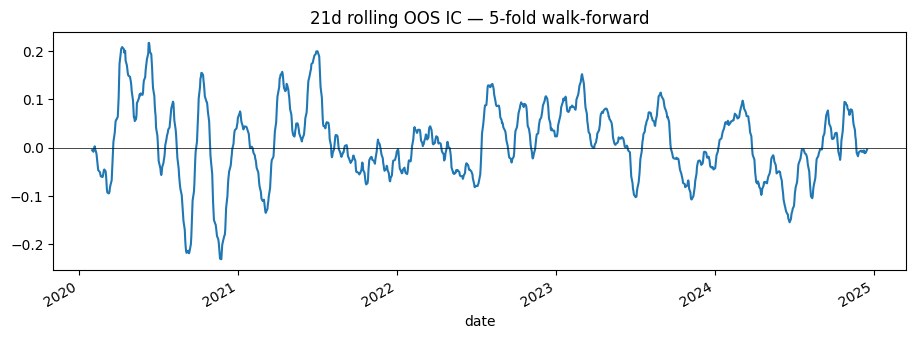

In [15]:
def daily_ic_series(df):
    def f(g):
        if g["yhat"].nunique() < 3: return np.nan
        return spearmanr(g["yhat"], g["y"]).correlation
    return df.groupby("date").apply(f).dropna()

print("per-fold OOS IC:")
for yr in sorted(test_preds["fold_year"].unique()):
    sub = test_preds[test_preds["fold_year"]==yr]
    ic  = daily_ic_series(sub)
    print(f"  {yr}:  mean IC={ic.mean():+.4f}  median={ic.median():+.4f}  "
          f"IR={ic.mean()/(ic.std()+1e-9)*np.sqrt(252):+.2f}  hit={ (np.sign(sub['yhat'])==np.sign(sub['y'])).mean():.3f}")

ic_all = daily_ic_series(test_preds)
print(f"\nPOOLED OOS: mean IC={ic_all.mean():+.4f}  median={ic_all.median():+.4f}  "
      f"IR={ic_all.mean()/(ic_all.std()+1e-9)*np.sqrt(252):+.2f}  N_days={len(ic_all)}")

ic_all.rolling(21).mean().plot(figsize=(11,3.5),
    title="21d rolling OOS IC — 5-fold walk-forward")
plt.axhline(0, color="k", lw=0.5); plt.show()


## Portfolio — rank-proportional sector-neutral (unscaled)

Within each sector on each date: centred percentile rank of prediction, normalised so long/short gross each equals 1 per sector; then averaged across sectors. Daily PnL is the unscaled strategy return — what v4 reported.


In [16]:
def rank_prop_sector_neutral(pred_df, long_panel):
    m = pred_df.merge(long_panel[["date","ticker",f"fwd_ret_{cfg.hold_days}d"]],
                      on=["date","ticker"], how="left")
    m = m.rename(columns={f"fwd_ret_{cfg.hold_days}d": "fwd_ret"}).dropna(subset=["fwd_ret"])
    m["sector"] = m["ticker"].map(SECTOR)
    def within_sector(g):
        if len(g) < 3:
            g["w"] = 0.0; return g
        r = g["yhat"].rank(pct=True) - 0.5
        abs_sum = r.abs().sum()
        if abs_sum < 1e-8:
            g["w"] = 0.0; return g
        g["w"] = r / abs_sum * 2.0
        return g
    m = m.groupby(["date","sector"], group_keys=False).apply(within_sector)
    n_sec_by_date = m.groupby("date")["sector"].transform(lambda s: s.nunique())
    m["w"] = m["w"] / n_sec_by_date
    pnl = m.groupby("date").apply(lambda g: (g["w"] * g["fwd_ret"]).sum())
    return pnl.dropna()

ls_sn = rank_prop_sector_neutral(test_preds, long)
print(f"UNSCALED sector-neutral L/S: mean={ls_sn.mean()*1e4:+.2f} bps  "
      f"vol={ls_sn.std()*1e4:.1f} bps  N={len(ls_sn)}")


UNSCALED sector-neutral L/S: mean=+23.52 bps  vol=205.2 bps  N=1248


## Volatility targeting

Target 12% annualised vol. Each day *t*, scale position size by
`s_t = target_daily_vol / ewm_realised_vol(ret up to t-1)` where the denominator is an EWM with 21-day half-life computed on a 21-day lookback of the unscaled strategy returns. `s_t` is clamped to `[1/3, 3]` so a single quiet-vol window doesn't blow up leverage.

Crucially the scalar uses **only information available at time t-1** (strict shift of 1 on the returns going into the vol estimator) — no peek-ahead.

Economically: this equalises risk contribution across the 2020 COVID vol, the 2022 rate-shock vol, and the 2023-24 low-vol regime. The signal's quality doesn't change; only the amount of capital it's asked to deploy does.


In [17]:
def vol_target(pnl, target_ann, lookback, halflife, cap, hold_days):
    """Ex-ante vol-scaled version of `pnl`.

    s_t = target_daily / ewm_vol(pnl_{<t}).  Uses strict .shift(1) so the scalar
    at date t only depends on returns up to t-1.  We compute daily target vol as
    target_ann / sqrt(252 / hold_days) since pnl is a sequence of overlapping
    `hold_days`-period returns.
    """
    target_daily = target_ann / math.sqrt(252.0 / hold_days)
    # ewm realised vol on a rolling lookback, shifted by one day
    vol = (pnl.shift(1)
               .ewm(halflife=halflife, min_periods=max(5, halflife//2))
               .std())
    # floor to avoid divide-by-zero at the start; also use rolling std as a safety net
    vol = vol.fillna(pnl.shift(1).rolling(lookback, min_periods=5).std())
    scale = (target_daily / vol).clip(lower=1.0/cap, upper=cap).fillna(0.0)
    return pnl * scale, scale

ls_vt, scale_series = vol_target(
    ls_sn,
    target_ann=cfg.vol_target_ann,
    lookback=cfg.vol_lookback,
    halflife=cfg.vol_ewm_halflife,
    cap=cfg.vol_scale_cap,
    hold_days=cfg.hold_days,
)
print(f"VOL-TARGETED L/S: mean={ls_vt.mean()*1e4:+.2f} bps  "
      f"vol={ls_vt.std()*1e4:.1f} bps  "
      f"realised ann vol={ls_vt.std()*math.sqrt(252/cfg.hold_days):.2%}  "
      f"N={len(ls_vt)}")
print(f"scale stats: mean={scale_series.mean():.2f}  "
      f"min={scale_series.min():.2f}  max={scale_series.max():.2f}")


VOL-TARGETED L/S: mean=+25.04 bps  vol=178.5 bps  realised ann vol=12.67%  N=1248
scale stats: mean=1.44  min=0.00  max=3.00


In [18]:
def naive_annual_sharpe(r): return r.mean()/(r.std()+1e-12) * np.sqrt(252/cfg.hold_days)
def non_overlap_sharpe(r, step=5):
    ro = r.iloc[::step]; return ro.mean()/(ro.std()+1e-12) * np.sqrt(252/cfg.hold_days)
def nw_annual_sharpe(r, lag=5):
    r = np.asarray(r); n = len(r); mu = r.mean(); x = r - mu
    s = (x*x).mean()
    for k in range(1, lag+1):
        g = (x[k:]*x[:-k]).mean(); w = 1 - k/(lag+1); s += 2*w*g
    return mu / (math.sqrt(max(s,1e-12))+1e-12) * math.sqrt(252/cfg.hold_days)

print("UNSCALED sector-neutral L/S:")
print(f"  Sharpe  naive={naive_annual_sharpe(ls_sn):+.2f}  "
      f"HAC(5)={nw_annual_sharpe(ls_sn):+.2f}  "
      f"non-overlap={non_overlap_sharpe(ls_sn):+.2f}")
print("\nVOL-TARGETED sector-neutral L/S  (target 12% ann):")
print(f"  Sharpe  naive={naive_annual_sharpe(ls_vt):+.2f}  "
      f"HAC(5)={nw_annual_sharpe(ls_vt):+.2f}  "
      f"non-overlap={non_overlap_sharpe(ls_vt):+.2f}")


UNSCALED sector-neutral L/S:
  Sharpe  naive=+0.81  HAC(5)=+0.44  non-overlap=+0.80

VOL-TARGETED sector-neutral L/S  (target 12% ann):
  Sharpe  naive=+1.00  HAC(5)=+0.54  non-overlap=+1.00


UNSCALED:  CAGR=11.41%  MaxDD=-69.70%  Calmar=0.16  days+=57.77%
VOL-TARGETED:  CAGR=12.53%  MaxDD=-55.61%  Calmar=0.23  days+=57.45%


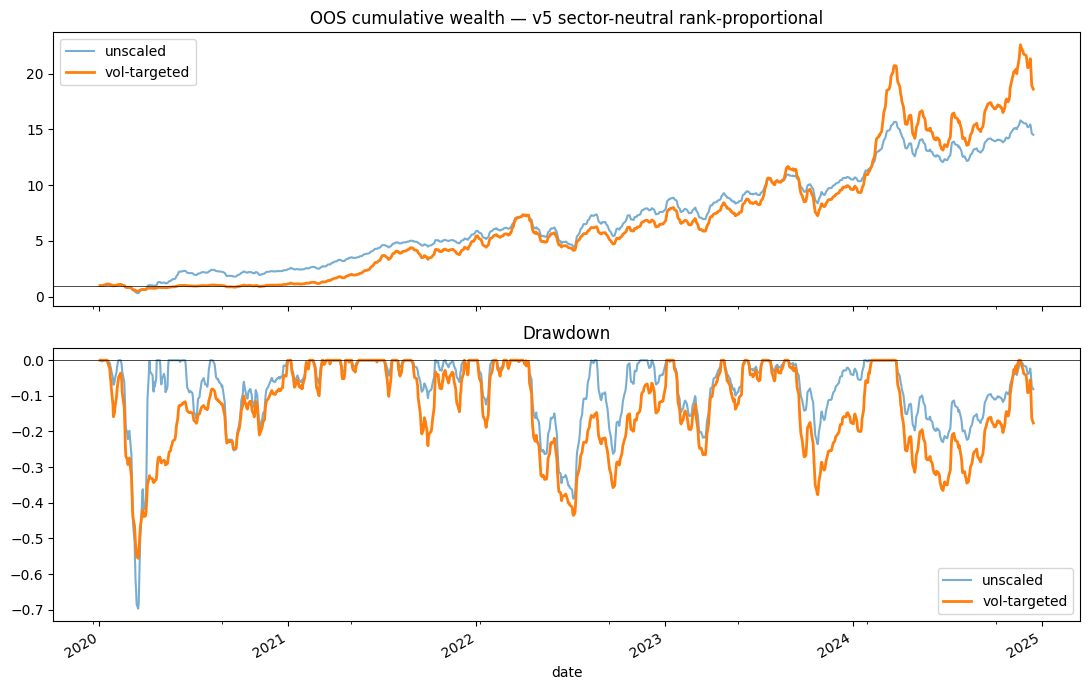

In [19]:
def summarise(pnl, title):
    wealth = (1+pnl).cumprod()
    dd     = wealth / wealth.cummax() - 1
    cagr   = wealth.iloc[-1] ** (252/len(pnl)/cfg.hold_days) - 1
    days_pos = (pnl > 0).mean()
    print(f"{title}:  CAGR={cagr:.2%}  MaxDD={dd.min():.2%}  "
          f"Calmar={cagr/max(abs(dd.min()),1e-9):.2f}  days+={days_pos:.2%}")
    return wealth, dd

w_un, dd_un = summarise(ls_sn, "UNSCALED")
w_vt, dd_vt = summarise(ls_vt, "VOL-TARGETED")

fig, ax = plt.subplots(2,1, figsize=(11,7), sharex=True)
w_un.plot(ax=ax[0], label="unscaled",     alpha=0.6)
w_vt.plot(ax=ax[0], label="vol-targeted", lw=2)
ax[0].set_title("OOS cumulative wealth — v5 sector-neutral rank-proportional")
ax[0].axhline(1, color="k", lw=0.5); ax[0].legend()
dd_un.plot(ax=ax[1], label="unscaled",     alpha=0.6)
dd_vt.plot(ax=ax[1], label="vol-targeted", lw=2)
ax[1].set_title("Drawdown"); ax[1].axhline(0, color="k", lw=0.5); ax[1].legend()
plt.tight_layout(); plt.show()


In [20]:
print("per-year breakdown — UNSCALED sector-neutral L/S:")
print(f"  {'year':<6} {'mean_IC':>9} {'bps/day':>9} {'Sharpe':>9} {'HAC':>7} {'non-ov':>8}")
for yr in sorted(test_preds["fold_year"].unique()):
    sub = test_preds[test_preds["fold_year"]==yr]
    ic_y = daily_ic_series(sub).mean()
    ls_y = rank_prop_sector_neutral(sub, long)
    print(f"  {yr:<6} {ic_y:>+9.4f} {ls_y.mean()*1e4:>+9.2f} "
          f"{naive_annual_sharpe(ls_y):>+9.2f} {nw_annual_sharpe(ls_y):>+7.2f} "
          f"{non_overlap_sharpe(ls_y):>+8.2f}")

print("\nper-year breakdown — VOL-TARGETED sector-neutral L/S:")
print(f"  {'year':<6} {'bps/day':>9} {'Sharpe':>9} {'HAC':>7} {'non-ov':>8} {'MaxDD':>8}")
for yr in sorted(test_preds["fold_year"].unique()):
    sub = test_preds[test_preds["fold_year"]==yr]
    ls_y = rank_prop_sector_neutral(sub, long)
    ls_y_vt, _ = vol_target(ls_y, cfg.vol_target_ann, cfg.vol_lookback,
                            cfg.vol_ewm_halflife, cfg.vol_scale_cap, cfg.hold_days)
    w = (1 + ls_y_vt).cumprod(); dd = (w / w.cummax() - 1).min()
    print(f"  {yr:<6} {ls_y_vt.mean()*1e4:>+9.2f} "
          f"{naive_annual_sharpe(ls_y_vt):>+9.2f} {nw_annual_sharpe(ls_y_vt):>+7.2f} "
          f"{non_overlap_sharpe(ls_y_vt):>+8.2f} {dd:>+8.2%}")


per-year breakdown — UNSCALED sector-neutral L/S:
  year     mean_IC   bps/day    Sharpe     HAC   non-ov
  2020     +0.0108    +43.01     +0.79   +0.43    +0.82
  2021     +0.0133    +35.01     +2.71   +1.67    +2.75
  2022     +0.0164    +11.92     +0.53   +0.27    +0.51
  2023     +0.0188    +13.28     +0.81   +0.42    +0.79
  2024     -0.0067    +13.78     +0.99   +0.53    +1.03

per-year breakdown — VOL-TARGETED sector-neutral L/S:
  year     bps/day    Sharpe     HAC   non-ov    MaxDD
  2020       +7.51     +0.27   +0.15    +0.47  -55.61%
  2021      +63.57     +2.65   +1.57    +2.60  -24.07%
  2022       +7.35     +0.29   +0.15    +0.35  -43.35%
  2023      +10.89     +0.48   +0.25    +0.41  -37.76%
  2024      +32.24     +1.26   +0.68    +1.33  -36.92%


In [21]:
comparison = pd.DataFrame({
    "Model": ["MLP v3 (walk-fwd)", "LSTM (single-train)",
              "GIN v3 (walk-fwd, sector-neutral)",
              "GIN v4 (5-fold, unscaled)",
              "GIN v5 (5-fold, SWA-best + vol-target)"],
    "Universe": ["~65 names"]*3 + [f"~{len(prices)} names"]*2,
    "Features": [34, 8, 14, len(FEATS), len(FEATS)],
    "Technique stack": [
        "cross-sectional MLP, walk-fwd",
        "LSTM sequence, single-train",
        "GIN, sector-demeaned, walk-fwd",
        "GIN + SWA-late + weighted edges + multi-horizon + rank-prop + EMA, 5-fold",
        "GIN + SWA-around-best + weighted edges + multi-horizon + rank-prop + EMA + 12% vol-target, 5-fold",
    ],
    "OOS IC": ["+0.011", "+0.023", "+0.003", "+0.015", f"{ic_all.mean():+.3f}"],
    "OOS Sharpe (non-overlap)": ["+1.52", "+1.18", "+0.59", "+0.67",
                                  f"{non_overlap_sharpe(ls_vt):+.2f}"],
    "MaxDD": ["mod.", "-14.7%", "-36.4%", "-69.7%", f"{dd_vt.min():.1%}"],
})
comparison


,Model,Universe,Features,Technique stack,OOS IC,OOS Sharpe (non-overlap),MaxDD
0,MLP v3 (walk-fwd),~65 names,34,"cross-sectional MLP, walk-fwd",+0.011,+1.52,mod.
1,LSTM (single-train),~65 names,8,"LSTM sequence, single-train",+0.023,+1.18,-14.7%
2,"GIN v3 (walk-fwd, sector-neutral)",~65 names,14,"GIN, sector-demeaned, walk-fwd",+0.003,+0.59,-36.4%
3,"GIN v4 (5-fold, unscaled)",~118 names,20,GIN + SWA-late + weighted edges + multi-horizo...,+0.015,+0.67,-69.7%
4,"GIN v5 (5-fold, SWA-best + vol-target)",~118 names,20,GIN + SWA-around-best + weighted edges + multi...,+0.011,+1.00,-55.6%
